In [2]:
import torch
import torch_geometric
from torch_geometric.data import Data
import random
import numpy as np

### Testing GraphBuilder

False
0.4230769230769231
4
[('A', 'B'), ('B', 'C'), ('C', 'A'), ('A', 'D'), ('D', 'B'), ('B', 'E'), ('E', 'C'), ('C', 'D'), ('D', 'E'), ('E', 'A'), ('A', 'X'), ('X', 4), (4, 0), (0, 1), (1, 2), (2, 0), (0, 3), (3, 1), (1, 4), (4, 2), (2, 3), (3, 4), (4, 5), (5, 0), (0, 6), (6, 1), (1, 5), (5, 2), (2, 6), (6, 3), (3, 5), (5, 6), (6, 4)]
[[4, 0, 1, 2, 3, 5, 6], [4, 'X'], ['C', 'A', 'D', 'B', 'E'], ['A', 'X']]
[('A', 'X'), (4, 'X')]
[{0, 1, 2, 3, 4, 5, 6, 'C', 'D', 'E', 'B', 'A', 'X'}]


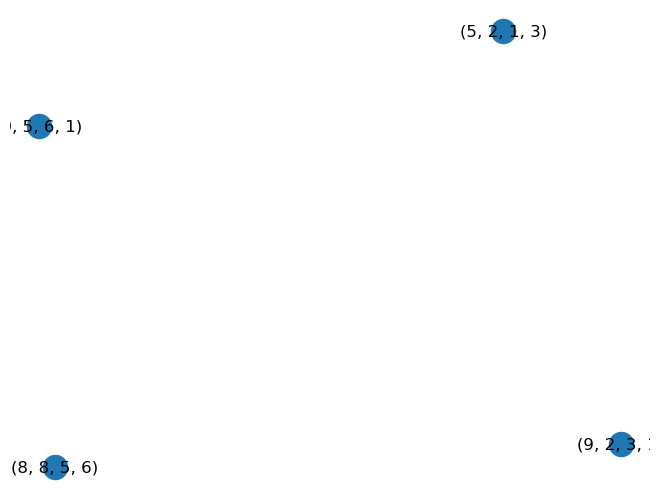

In [3]:
import json
from graphgen import GraphBuilder
import networkx as nx
import matplotlib.pyplot as plt

config = json.load(open("../res/graphgen_config.json",'r'))
print(config['directed'])

edge_list = [(1,2), (2,3), (3,4), (3,5), (2,5), (4,6), (6,7)]

# arr = (
#    [0, 1, 0],
#    [1, 1, 1],
#    [0, 0, 0]
# ])

# G = nx.from_numpy_array(arr)

G = nx.DiGraph()
G.add_edges_from(edge_list)
# G = nx.complete_graph(10)

G1 = nx.complete_graph(5)
G2 = nx.complete_graph(7)
G1 = nx.relabel_nodes(G1, {0: "A", 1: "B", 2: "C", 3: "D", 4: "E"})
G_connector = nx.from_edgelist([(4, "X"), ("X", "A")])

G = nx.compose_all([G1, G2, G_connector])

G3 = nx.Graph()
G3.add_node((0,5,6,1))
G3.add_node((5,2,1,3))
G3.add_node((9,2,3,1))
G3.add_node((8,8,5,6))

# print(nx.adjacency_matrix(G))
# print(f'In_Degree of node[2] = {dict(G.in_degree)[2]}')
# print(nx.shortest_path(G, 2,5))
print(nx.density(G))
print(nx.diameter(G))
print(list(nx.eulerian_path(G)))
print(list(nx.find_cliques(G)))
print(list(nx.bridges(G)))
print(list(nx.connected_components(G))) # also weakly and strongly with directed graphs

nx.draw_spring(G3, with_labels=True)
# nx.draw_circular(G, with_labels=True)
# nx.draw_shell(G, with_labels=True)
# nx.draw_spectral(G, with_labels=True)
# nx.draw_random(G, with_labels=True)
# nx.draw_planar(G, with_labels=True) # No edges intersecting

plt.show()

### Testing graph manipulation

In [ ]:
data = Data(x = torch.tensor([[0,2,5], [3,1,4], [9,2,1], [7,2,3], [3,7,9], [5,1,1], [2,3,5], [1,6,6]]),
            edge_index = torch.tensor([[2,5], [1,3], [3,1], [1,2], [4,6], [8,10]])
            )

print(data.edge_index.shape[0])

node_indices = data.edge_index.flatten().unique()
all_possible_edges = torch.cartesian_prod(node_indices, node_indices)

mask = torch.ones(len(all_possible_edges), dtype=torch.bool)
for i in range(len(data.edge_index)):
    mask &= ~(all_possible_edges == data.edge_index[i]).all(dim=1)
result = all_possible_edges[mask]

filtered = result[result[:, 0] != result[:, 1]]

In [ ]:
edges_to_add = result[np.random.choice(result.shape[0], size=5, replace=False)]
print(data.edge_index)
print(edges_to_add)
data.edge_index = torch.cat((data.edge_index, edges_to_add))
data.edge_index

In [ ]:
ind = node_indices[np.random.choice(node_indices.shape[0], size=2, replace=False)]
ind = torch.tensor([3,1])
print(ind)
print(data.edge_index)
not_present = not torch.eq(ind, data.edge_index).all(1).any().item()
print(f"Edge isn't contained: {not_present}")

In [ ]:
tens = torch.tensor([[0,1], [2,3], [6,4]])
res = node_indices[np.random.choice(node_indices.shape[0], size=2, replace=False)].unsqueeze(0)
print(tens)
print(res)
torch.cat((tens, res), dim=0)

In [ ]:
import random as rn
G = nx.Graph()
G.add_node(0, attr=tuple(round(rn.random() * 10) for _ in range(5)))
G.add_node(1, attr=tuple(round(rn.random() * 10) for _ in range(5)))
G.add_edge(0,1)
print(nx.adjacency_matrix(G))
print(G.nodes(data=True))

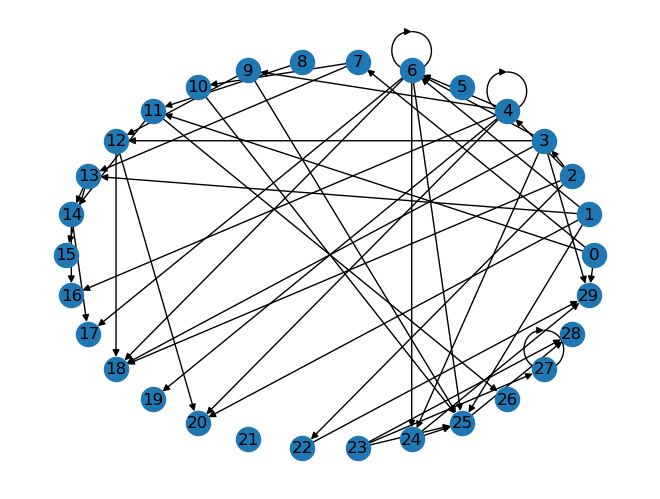

In [7]:
from graphgen.GraphBuilder import GraphBuilder

json_path = '../res/graphgen_config.json'
gb = GraphBuilder(json_path)
data = gb.build()

nxdata = torch_geometric.utils.to_networkx(data)
nx.draw_circular(nxdata, with_labels=True)
plt.show()

In [2]:
import json
import networkx as nx
import torch 

conf = json.load(open(json_path, 'r'))

graph = nx.Graph()
graph.add_edge(0, 1, attr=(1, 2, 3))
graph.add_edge(1, 2, attr=(4, 5, 6))
graph.add_node(0, attr=(0, 1, 2, 3))
graph.add_node(1, attr=(4, 5, 6, 7))
graph.add_node(2, attr=(8, 9, 10, 11))
print(graph.edges)
print(torch.tensor(list(graph.edges)).t().contiguous())

data.edge_attr

[(0, 1), (1, 2)]
tensor([[0, 1],
        [1, 2]])


tensor([[ 0,  8,  7,  7],
        [ 5,  2,  5,  3],
        [ 1,  3,  4,  9],
        [ 4,  2,  6,  8],
        [ 5, 10,  6,  4],
        [ 5,  8,  4,  4],
        [ 2,  5,  1,  1],
        [ 1,  5,  9,  4],
        [ 7,  7,  1,  4],
        [ 0,  6,  4,  6],
        [ 4,  7,  8,  8],
        [10,  3,  4,  2],
        [ 7,  6,  4,  3],
        [ 9,  8,  8,  9],
        [ 8,  1,  4,  6],
        [ 5,  2,  1,  2],
        [ 4, 10,  1,  8],
        [ 7,  2,  7,  2],
        [ 5,  8,  5,  4],
        [ 4,  4,  4,  3]])